# Brain Tumour MRI Screening
### Binary classification (tumour vs. no tumour) with a fine-tuned ResNet-18

**Author:** *Bilawal makhdoom*  |  **Platform:** Kaggle notebook (CUDA GPU)

> *Educational project. The model is not a medical device and must not be used for diagnosis.*

---

## Project at a glance

| Item | Details |
|---|---|
| **Goal** | Flag MRI slices that show a tumour, while keeping missed tumours to a minimum |
| **Data** | Kaggle dataset `bilawalmakhdoom/brain-tumor`: 7,200 MRI slices in four folders (glioma, meningioma, pituitary, notumor), 1,800 images each |
| **Task framing** | The three tumour folders are merged into one **tumor** class; **notumor** becomes **no_tumor** |
| **Model** | ResNet-18 pretrained on ImageNet, two-phase transfer learning |
| **Main metric** | Macro-F1 (accuracy alone would be misleading, see Section 3) |
| **Explainability** | Grad-CAM heat-maps |

## Headline results (held-out test set, 744 images)

| Metric | Default decision rule | Tuned threshold (t = 0.986) |
|---|---|---|
| Accuracy | 0.989 | n/a |
| Macro-F1 | 0.961 | n/a |
| Tumour sensitivity (recall) | 0.997 | 0.968 |
| Specificity | 0.895 | 0.965 |
| ROC-AUC | n/a | 0.994 |

## Contents

1. Experiment configuration
2. Environment setup
3. Dataset indexing and class balance
4. Exploratory data analysis
5. Group structure check
6. Exact duplicate detection
7. Duplicate removal
8. Train / validation / test split
9. Near-duplicate leakage audit
10. Pre-processing and augmentation
11. Handling class imbalance
12. Model construction
13. Two-phase training
14. Test-set evaluation
15. Choosing an operating threshold
16. Grad-CAM: first look
17. Grad-CAM: one example per tumour type
18. Saving the model
19. Summary, limitations and next steps

---
## 1. Experiment Configuration

**Purpose.** Keep every setting that can change the experiment in a single cell, so a different dataset or backbone needs edits here and nowhere else.

| Parameter | Value in this run | Role |
|---|---|---|
| `DATA_ROOT` / `TRAIN_DIR` | `/kaggle/input/datasets/bilawalmakhdoom/brain-tumor` | Folder that contains the class sub-folders |
| `TEST_DIR` | `None` | No separate test folder exists, so a test set is carved out of the data later |
| `GRAYSCALE` | `True` | MRI slices are grey-scale, but the files mix L, RGB and RGBA modes |
| `IMG_SIZE` | 224 | Input resolution expected by ResNet-18 |
| `BACKBONE` | `resnet18` | Pretrained feature extractor |
| `GROUP_PATTERN` | `None` | File names such as `Te-gl_1.jpg` carry no patient ID, so no grouping is possible |
| `BINARY` | `True` | Merge the four folders into two classes |
| `NORMAL_KEYWORD` | `notumor` | Any folder whose name contains this word is the healthy class |
| `POSITIVE` | `tumor` | The class that must not be missed |
| `TARGET_RECALL` | 0.95 | Minimum tumour sensitivity required when the threshold is tuned (Section 15) |

In [13]:

DATA_ROOT = '/kaggle/input/datasets/bilawalmakhdoom/brain-tumor'   # folder with the 4 class folders
TRAIN_DIR = DATA_ROOT        # folder whose subfolders are the class folders (glioma, meningioma, notumor, pituitary)
TEST_DIR = None              # no separate test folder -> the code carves a test set
GRAYSCALE = True             # MRI scans are grey-scale (the folder mixes L / RGB / RGBA files)
IMG_SIZE = 224
BACKBONE = 'resnet18'
# File names look like 'Te-gl_1.jpg' / 'Tr-pi_984.jpg': there is no patient id in the name,
# so no grouping is possible -> every image is its own group.
GROUP_PATTERN = None
BINARY = True                # True: merge the 4 folders into 'no_tumor' vs 'tumor'
NORMAL_KEYWORD = 'notumor'   # a folder whose name contains this is the healthy class
NORMAL_LABEL = 'no_tumor'
POSITIVE = 'tumor'           # the class that must not be missed
TARGET_RECALL = 0.95
# ======================================================================

---
## 2. Environment Setup

**Purpose.** Load the libraries and make the run reproducible.

- **PyTorch / torchvision** provide the model, the data pipeline and the image transforms.
- **scikit-learn** supplies the splitter and the evaluation metrics.
- **Pillow and matplotlib** handle image loading and plotting.
- **Seeds:** `torch.manual_seed(42)` and `np.random.seed(42)` fix weight initialisation, shuffling and the splits.

**Result.** The cell prints `Device: cuda`, so training runs on a GPU. Later cells confirm the benefit: one training epoch takes roughly 24 seconds.

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


---
## 3. Dataset Indexing and Class Balance

**Purpose.** Walk through the dataset folder and build a table with one row per image: file path, merged label, original folder, file name and group ID.

**Observed result**

| Original folder | Images | Merged label |
|---|---|---|
| glioma | 1,800 | tumor |
| meningioma | 1,800 | tumor |
| pituitary | 1,800 | tumor |
| notumor | 1,800 | no_tumor |
| **Total** | **7,200** | no_tumor = 1,800, tumor = 5,400 |

- **Imbalance ratio: 3.0** (5,400 / 1,800). The four original folders are perfectly balanced, but merging them creates a 3 : 1 tumour-heavy problem.
- **Images per group: 1.00**, because every file name is its own group (no patient ID is available).

**Why this matters.** A model that always answered "tumour" would already be right for 5,400 / 7,200 = 75% of images while detecting no healthy scan at all. Accuracy therefore cannot be the headline metric here; macro-F1, sensitivity and specificity are used instead.

In [3]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif')

def find_class_dirs(folder):
    """Return every sub-folder that directly contains images (= a class folder).
    Works whether the class folders sit directly in `folder` or one/two levels deeper
    (e.g. Kaggle's  <dataset>/<subfolder>/<class>/...)."""
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f'{folder} does not exist. Attach the dataset via "Add Input" in the Kaggle '
            f'sidebar, then copy its real path and set DATA_ROOT in the config cell.')
    dirs = []
    for root, subdirs, files in os.walk(folder):
        if any(f.lower().endswith(IMG_EXT) for f in files):
            dirs.append(root)
    if not dirs:
        raise FileNotFoundError(
            f'No images found under {folder}. Contents: {os.listdir(folder)[:10]}. '
            f'Set DATA_ROOT/TRAIN_DIR to the folder that holds the class folders.')
    return sorted(dirs)

def index_folder(folder):
    """One row per image: path, label, original class folder, file name, group id."""
    rows = []
    for cdir in find_class_dirs(folder):
        cls = os.path.basename(cdir)
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(IMG_EXT):
                if BINARY:
                    label = NORMAL_LABEL if NORMAL_KEYWORD in cls.lower() else POSITIVE
                else:
                    label = cls
                rows.append({'path': os.path.join(cdir, f), 'label': label,
                             'orig_class': cls, 'file': f})
    df = pd.DataFrame(rows)
    assert len(classes_found := df['label'].unique()) >= 2 or not BINARY, \
        f'Only one class found {list(classes_found)}: check NORMAL_KEYWORD / folder names'
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])          # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('\nOriginal class folders:')
print(train_df['orig_class'].value_counts().to_string())
print('\nGroup regex check:')
print(train_df[['file', 'group']].head(10).to_string())

label
no_tumor    1800
tumor       5400
Imbalance ratio (max / min): 3.0
Images per group: 1.00

Original class folders:
orig_class
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800

Group regex check:
            file          group
0    Te-gl_1.jpg    Te-gl_1.jpg
1   Te-gl_10.jpg   Te-gl_10.jpg
2  Te-gl_100.jpg  Te-gl_100.jpg
3  Te-gl_101.jpg  Te-gl_101.jpg
4  Te-gl_102.jpg  Te-gl_102.jpg
5  Te-gl_103.jpg  Te-gl_103.jpg
6  Te-gl_104.jpg  Te-gl_104.jpg
7  Te-gl_105.jpg  Te-gl_105.jpg
8  Te-gl_106.jpg  Te-gl_106.jpg
9  Te-gl_107.jpg  Te-gl_107.jpg


---
## 4. Exploratory Data Analysis: Image Properties and Samples

**Purpose.** Check what the raw images look like before designing the pipeline. The cell opens 300 random files to read their size and colour mode, then plots five random examples per class.

**Observed result (300-image sample)**

| Statistic | Width (px) | Height (px) |
|---|---|---|
| Minimum | 173 | 183 |
| Median | 512 | 512 |
| Maximum | 1,338 | 1,304 |

Colour modes: **RGB 168, L (grey) 131, RGBA 1**.

**Interpretation**

- Resolutions differ by almost an order of magnitude, so all images must be resized to one fixed size.
- More than half of the files are stored as RGB even though MRI is a single-channel modality. Converting everything to grey-scale and then repeating it to three channels gives ResNet-18 a consistent input.
- The sample grid also shows different scan planes and contrast settings across images, which justifies the augmentation chosen in Section 10.

          w       h
min   173.0   183.0
50%   512.0   512.0
max  1338.0  1304.0
Colour modes: {'RGB': 168, 'L': 131, 'RGBA': 1}


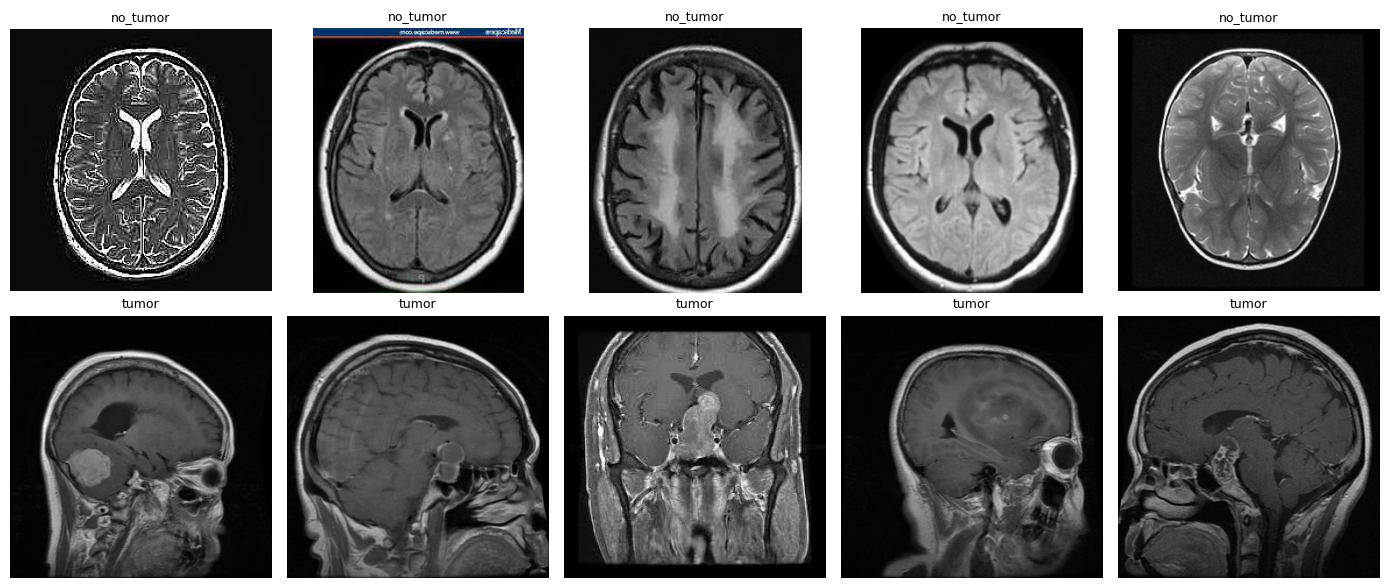

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

---
## 5. Group Structure Check

**Purpose.** Confirm whether any images share a group ID. Grouping matters because several slices from one patient must never be split between training and evaluation.

**Observed result**

- Groups containing more than one image: **0**.
- The ten largest groups all hold exactly one image.

**Interpretation.** Group-aware splitting has nothing to work with, so it behaves like an ordinary stratified random split. Slices from the same patient could still sit under different file names. The next three sections therefore look for duplicates by **image content** rather than by file name.

In [5]:
g = train_df.groupby('group').size().sort_values(ascending=False)
print('Groups with more than 1 image:', (g > 1).sum())
print(g.head(10).to_string())
print(train_df[train_df['group'] == g.index[0]][['orig_class', 'file']].to_string())

Groups with more than 1 image: 0
group
Tr-pi_963.jpg    1
Tr-pi_964.jpg    1
Tr-pi_965.jpg    1
Tr-pi_966.jpg    1
Tr-pi_967.jpg    1
Tr-pi_968.jpg    1
Tr-pi_969.jpg    1
Tr-pi_97.jpg     1
Tr-pi_956.jpg    1
Tr-pi_957.jpg    1
     orig_class           file
7160  pituitary  Tr-pi_963.jpg


---
## 6. Exact Duplicate Detection

**Purpose.** Find byte-identical files by computing an MD5 hash of every image. Identical hashes mean identical files, whatever their names are.

The cell also defines `fingerprint`, a 32 x 32 standardised grey thumbnail used in Section 9 to catch images that are *almost* identical (resized, re-compressed or brightness-shifted).

**Observed result**

| Quantity | Value |
|---|---|
| Files involved in exact duplication | 340 |
| Sets of identical files | 153 |
| Redundant copies (340 - 153) | **187** |
| Identical files with different labels | **0** |

**Interpretation.** About 2.6% of the dataset (187 of 7,200) is redundant. The listed examples come from the *pituitary* and *notumor* folders. The absence of label conflicts is reassuring: no image is filed as both tumour and healthy.

In [6]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df.copy()
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
print('Duplicate groups (sets of identical files):', exact['md5'].nunique())
if len(exact):
    print(exact.sort_values('md5')[['orig_class', 'file', 'md5']].head(20).to_string())
    conflict = exact.groupby('md5')['label'].nunique()
    print('Identical files with DIFFERENT labels:', (conflict > 1).sum())

Exact duplicate files: 340
Duplicate groups (sets of identical files): 153
     orig_class            file                               md5
6408  pituitary   Tr-pi_286.jpg  00748c6aaa5c199b07f8fa7140fc19c1
6531  pituitary   Tr-pi_397.jpg  00748c6aaa5c199b07f8fa7140fc19c1
6431  pituitary   Tr-pi_306.jpg  008c98403b057fc344bf0a9f2e7de6c2
6279  pituitary    Tr-pi_17.jpg  008c98403b057fc344bf0a9f2e7de6c2
5974  pituitary  Tr-pi_1155.jpg  0140560cc9a91abc3e62e9e1bec6c5ea
5910  pituitary  Tr-pi_1098.jpg  0140560cc9a91abc3e62e9e1bec6c5ea
7071  pituitary   Tr-pi_883.jpg  05c3caea567ffd77caf79c12654b87e5
6569  pituitary   Tr-pi_430.jpg  05c3caea567ffd77caf79c12654b87e5
6337  pituitary   Tr-pi_221.jpg  05c3caea567ffd77caf79c12654b87e5
4838    notumor  Tr-no_1393.jpg  05fe39a899414d2dab6cad25c301b32c
5404    notumor   Tr-no_642.jpg  05fe39a899414d2dab6cad25c301b32c
5411    notumor   Tr-no_649.jpg  06c3e21e888012e7845da47b26b742e8
5598    notumor   Tr-no_817.jpg  06c3e21e888012e7845da47b26b742e8
5

---
## 7. Duplicate Removal

**Purpose.** Keep the first copy of every distinct file and discard the rest, so that no image can appear on both sides of a split.

**Observed result:** 187 copies removed, **7,013 images remain**.

$$7{,}200 - 187 = 7{,}013 \quad (97.4\%\ \text{of the data retained})$$

In [7]:
# Keep one copy of each byte-identical file
train_df['md5'] = all_df['md5'].values[:len(train_df)]   # train rows come first in all_df
before = len(train_df)
train_df = train_df.drop_duplicates('md5', keep='first').reset_index(drop=True)
print(f'Removed {before - len(train_df)} duplicate copies; {len(train_df)} images remain')

Removed 187 duplicate copies; 7013 images remain


---
## 8. Train / Validation / Test Split

**Purpose.** Create three disjoint sets with the same class ratio. `StratifiedGroupKFold(n_splits=6)` is used twice: the first fold becomes the validation set; the same procedure on the remainder yields the test set.

**Observed result**

| Set | Images | Share of 7,013 |
|---|---|---|
| Train | 4,870 | 69.4% |
| Validation | 1,169 | 16.7% |
| Test | 974 | 13.9% |

- Groups shared between train and validation: **0**; between train and test: **0**.
- Validation labels: **tumor 889, no_tumor 280**.

**Caveat.** Because every image is its own group, the "0 shared groups" check is true by construction. It does **not** prove that no patient appears in two sets. Section 9 addresses this directly.

In [8]:
# Validation split BY GROUP: no leaf appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                         # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))
print(va_df['label'].value_counts().to_string())

train 4870 | val 1169 | test 974
Groups shared by train and val: 0
Groups shared by train and test: 0
label
tumor       889
no_tumor    280


---
## 9. Near-Duplicate Leakage Audit

**Purpose.** Exact hashes miss images that were re-saved or lightly edited. Every image is converted to a 1,024-value fingerprint, and for each validation or test image the nearest **training** image is found using the mean absolute difference

$$d(a,b)=\frac{1}{1024}\sum_{i=1}^{1024}|a_i-b_i|$$

An image is a near-duplicate when $d < 0.10$. The closest pairs are plotted before anything is deleted, so the decision can be checked by eye.

**Observed result**

| Set | Near-duplicates of a training image | Share |
|---|---|---|
| Test | 230 of 974 | 23.6% |
| Validation | 260 of 1,169 | 22.2% |

The ten smallest test distances are all 0.000, meaning the thumbnails are identical. Fingerprinting finished in 11 seconds on the GPU.

**Sets after removal:** train 4,870 | validation **909** | test **744**.

| Class | Validation before | Validation after | Removed |
|---|---|---|---|
| tumor | 889 | 840 | 49 (5.5%) |
| no_tumor | 280 | 69 | **211 (75.4%)** |

**Key insight.** The leakage was concentrated in the healthy class: three out of four validation *no_tumor* images had a twin in the training data. Leaving them in would have inflated every healthy-class metric. The price is that the healthy class is now represented by only **69 validation** and **57 test** images, so metrics for that class carry noticeable statistical uncertainty. Only validation and test are filtered; the training set keeps all of its images.

Fingerprints done in 11s
Test images with a near-duplicate in train: 230 of 974
Val images with a near-duplicate in train:  260 of 1169
Closest test distances: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


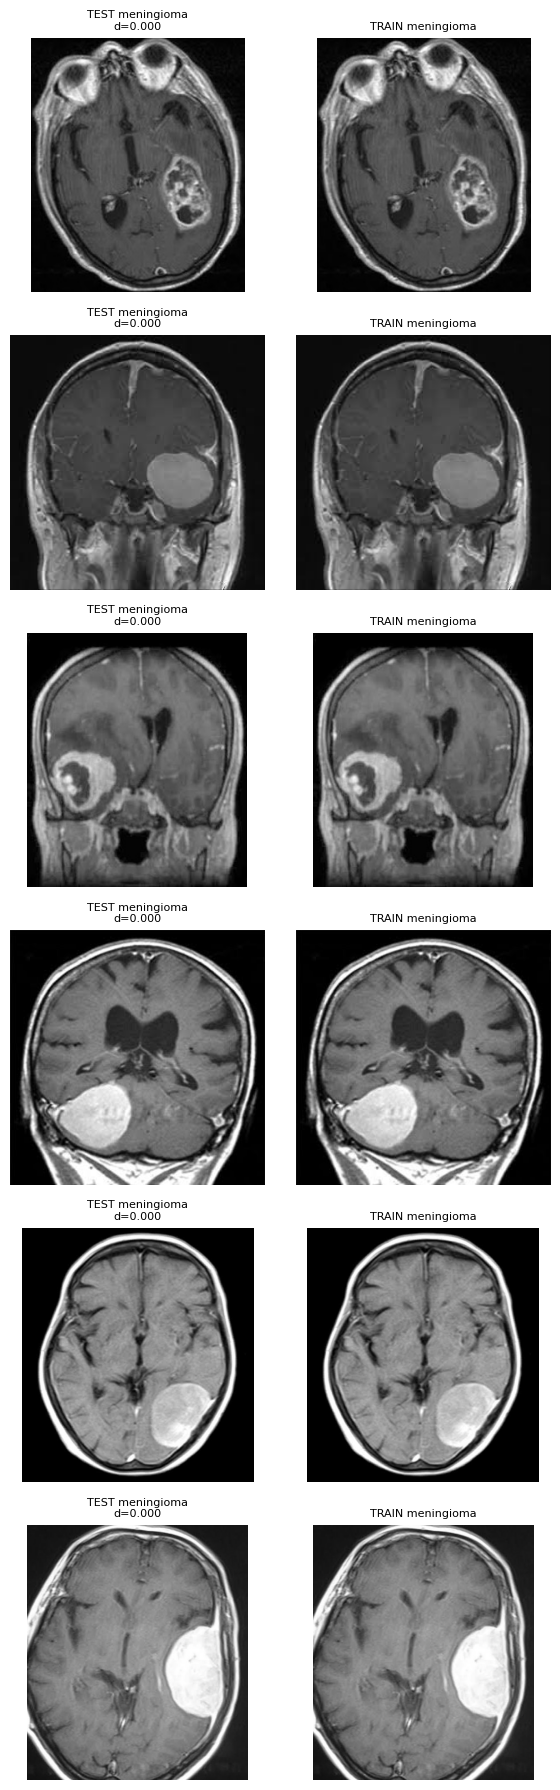

After removal: train 4870 | val 909 | test 744
Val labels: {'tumor': 840, 'no_tumor': 69} | Test labels: {'tumor': 687, 'no_tumor': 57}


In [9]:
# Near-duplicate check between the carved splits (needed because TEST_DIR = None)
def fp_matrix(df):
    return torch.tensor(np.stack([fingerprint(p) for p in df['path']]),
                        dtype=torch.float32, device=device)

def nearest(A, B, chunk=512):
    """For each row of A: mean absolute difference to its closest row of B, and that row's index."""
    dists, idxs = [], []
    for i in range(0, len(A), chunk):
        d = torch.cdist(A[i:i + chunk], B, p=1) / A.shape[1]
        m, j = d.min(1)
        dists.append(m.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists).numpy(), torch.cat(idxs).numpy()

t0 = time.time()
FP_tr, FP_va, FP_te = fp_matrix(tr_df), fp_matrix(va_df), fp_matrix(test_df)
print(f'Fingerprints done in {time.time() - t0:.0f}s')

d_te, j_te = nearest(FP_te, FP_tr)
d_va, j_va = nearest(FP_va, FP_tr)
near_te, near_va = d_te < 0.10, d_va < 0.10
print(f'Test images with a near-duplicate in train: {near_te.sum()} of {len(test_df)}')
print(f'Val images with a near-duplicate in train:  {near_va.sum()} of {len(va_df)}')
print('Closest test distances:', np.sort(d_te)[:10].round(3))

# Inspect the closest pairs BEFORE deleting anything
order = np.argsort(d_te)[:6]
fig, axes = plt.subplots(len(order), 2, figsize=(6, 3 * len(order)))
for r, k in enumerate(order):
    a, b = test_df.iloc[k], tr_df.iloc[j_te[k]]
    axes[r, 0].imshow(Image.open(a['path']).convert('RGB'))
    axes[r, 0].set_title(f"TEST {a['orig_class']}\nd={d_te[k]:.3f}", fontsize=8)
    axes[r, 1].imshow(Image.open(b['path']).convert('RGB'))
    axes[r, 1].set_title(f"TRAIN {b['orig_class']}", fontsize=8)
    axes[r, 0].axis('off')
    axes[r, 1].axis('off')
plt.tight_layout()
plt.show()
# Remove val/test images that have a near-duplicate in train (they would inflate the scores)
test_df = test_df[~near_te].reset_index(drop=True)
va_df = va_df[~near_va].reset_index(drop=True)
print(f'After removal: train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Val labels:', va_df['label'].value_counts().to_dict(),
      '| Test labels:', test_df['label'].value_counts().to_dict())

---
## 10. Pre-processing and Augmentation

**Purpose.** Turn images into normalised 224 x 224 tensors, add random variation to the training images only, and wrap each split in a PyTorch `Dataset`.

| Step | Training pipeline | Evaluation pipeline |
|---|---|---|
| Channels | Grey-scale repeated to 3 channels | Same |
| Geometry | Random resized crop (scale 0.8 to 1.0), horizontal and vertical flips, rotation up to 20 degrees | Plain resize to 224 x 224 |
| Intensity | Brightness and contrast jitter of 0.15 | None |
| Scaling | ImageNet mean / std normalisation | Same |

- **Hue and saturation are not jittered.** The data is grey-scale, so colour shifts would only add noise.
- Normalisation uses the ImageNet statistics because the backbone was pretrained with them: mean (0.485, 0.456, 0.406), std (0.229, 0.224, 0.225).

**Observed result:** train 4,870 | validation 909 | test 744. Class order is `['no_tumor', 'tumor']`, so output index 0 is healthy and index 1 is tumour.

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),   # no hue/saturation: colour is disease evidence
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')
print('Class order:', classes)

train 4870 | val 909 | test 744
Class order: ['no_tumor', 'tumor']


---
## 11. Handling Class Imbalance

**Purpose.** Stop the optimiser from favouring the majority class. Each class receives a loss weight inversely proportional to its frequency:

$$w_c = \frac{N}{K \cdot n_c}$$

with $N$ = training images, $K$ = classes and $n_c$ = images of class $c$.

**Observed result**

| Class | Training images | Weight | Total influence ($n_c \times w_c$) |
|---|---|---|---|
| no_tumor | 1,167 | **2.087** | about 2,435 |
| tumor | 3,703 | **0.658** | about 2,437 |

Both classes now contribute the same total weight to the loss, so a healthy scan counts about 3.2 times as much as a tumour scan during training.

**Design note.** The cell also contains a switch, `USE_SAMPLER`, that replaces weighted loss with balanced sampling. It is left at `False` in this run. DataLoaders use batch size 32 for training and 64 for validation and test.

In [15]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('Images per class in train:', dict(zip(classes, n_c)))
print('Class weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True later: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                     # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

Images per class in train: {'no_tumor': np.int64(1167), 'tumor': np.int64(3703)}
Class weights: {'no_tumor': np.float64(2.087), 'tumor': np.float64(0.658)}


---
## 12. Model Construction

**Purpose.** Build the classifier from a pretrained ResNet-18 in three steps:

1. Obtain ImageNet weights.
2. Replace the 1,000-class output layer with `Linear(512, 2)`.
3. **Freeze** the whole backbone and un-freeze only the new head.

**Observed result**

- No local weight file was found under `/kaggle/input`, so the notebook **downloaded** `resnet18-f37072fd.pth` (44.7 MB) from the PyTorch servers. This only works with **Internet enabled** in the Kaggle session settings.
- Trainable parameters: **1,026**.

$$\underbrace{512 \times 2}_{\text{weights}} + \underbrace{2}_{\text{biases}} = 1{,}026$$

**Why freeze first.** Training only the head lets the new layer find a sensible starting point without disturbing the pretrained features. The final convolutional block is un-frozen in the next section.

In [11]:
import glob

def find_weights(name):
    """Search /kaggle/input (recursively) and the torch cache for a .pth/.pt file of this backbone."""
    key = name.replace('_', '').replace('-', '').lower()
    roots = ['/kaggle/input', os.path.expanduser('~/.cache/torch/hub/checkpoints')]
    hits = []
    for root in roots:
        for dp, _, fs in os.walk(root):
            for f in fs:
                if f.lower().endswith(('.pth', '.pt')):
                    full = os.path.join(dp, f)
                    if key in full.lower().replace('_', '').replace('-', ''):
                        hits.append(full)
    # prefer the official ImageNet file (e.g. resnet18-f37072fd.pth) over fine-tuned ones
    pref = name.replace('_', '') + '-'
    hits.sort(key=lambda p: (not os.path.basename(p).lower().startswith(pref), p))
    print('Weight files found:', hits)
    if not hits:
        mdir = '/kaggle/input/models'
        print('Nothing matched. /kaggle/input contains:', os.listdir('/kaggle/input')
              if os.path.isdir('/kaggle/input') else 'N/A')
        if os.path.isdir(mdir):
            for dp, _, fs in os.walk(mdir):
                for f in fs:
                    print('  model file:', os.path.join(dp, f))
    return hits[0] if hits else None

def load_local(m, path):
    """Load a .pth/.pt file into model m, skipping any tensor whose shape does not match
    (e.g. the 1000-class or 6-class fc layer of a different checkpoint)."""
    obj = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(obj, nn.Module):                 # file holds a whole model
        obj = obj.state_dict()
    if isinstance(obj, dict) and 'state_dict' in obj:
        obj = obj['state_dict']
    obj = {k.replace('module.', ''): v for k, v in obj.items()}
    own = m.state_dict()
    ok = {k: v for k, v in obj.items() if k in own and own[k].shape == v.shape}
    skipped = [k for k in obj if k not in ok]
    result = m.load_state_dict(ok, strict=False)
    print('Loaded', len(ok), 'tensors from', os.path.basename(path))
    print('Skipped (shape/name mismatch):', skipped)
    print('Missing keys:', result.missing_keys)
    return m

def get_backbone(name, ctor, weights_enum):
    local = find_weights(name)
    if local:
        return load_local(ctor(weights=None), local)
    try:                                           # needs internet
        return ctor(weights=weights_enum.DEFAULT)
    except Exception as e:
        raise RuntimeError(
            f'No local {name} weights found and the download failed ({type(e).__name__}). '
            f'Fix: in the Kaggle sidebar click "Add Input" -> Models -> search "{name}" '
            f'(PyTorch) and add it, OR turn on Settings -> Internet.') from None

def build_model(name, n_classes):
    if name == 'resnet18':
        m = get_backbone(name, models.resnet18, models.ResNet18_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = get_backbone(name, models.resnet50, models.ResNet50_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        m = get_backbone(name, models.efficientnet_b0, models.EfficientNet_B0_Weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Weight files found: []
Nothing matched. /kaggle/input contains: ['datasets']
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s] 


resnet18 trainable: 1026


---
## 13. Two-Phase Training

**Strategy.** Adam optimiser with class-weighted cross-entropy. After every epoch the model is scored on the validation set with **macro-F1**, and the best weights are restored at the end of each phase.

| Phase | Trainable part | Learning rate | Epochs |
|---|---|---|---|
| 1. Head only | New `fc` layer | 1e-3 | 2 |
| 2. Partial fine-tuning | `layer4` and `fc` | 1e-4 and 1e-3 | 3 |

**Observed result (validation macro-F1)**

| Epoch | Phase 1 | Phase 2 |
|---|---|---|
| 1 | 0.903 | **0.924** |
| 2 | 0.846 | 0.904 |
| 3 | n/a | 0.913 |

**Interpretation**

- Fine-tuning `layer4` lifted the best score from 0.903 to **0.924**.
- The final model is the **Phase 2, epoch 1** checkpoint, because that epoch had the highest validation score; epochs 2 and 3 were not kept.
- Scores move by up to 0.08 between epochs. That is expected here: the validation set contains only 69 healthy images, so a few predictions swing the healthy-class F1 considerably.
- Each epoch took 23 to 25 seconds; the full run finished in about two minutes.

In [16]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')      # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.903 (25s)
epoch 2: val macro-F1 0.846 (24s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.924 (24s)
epoch 2: val macro-F1 0.904 (24s)
epoch 3: val macro-F1 0.913 (23s)


0.9239849475143593

---
## 14. Test-Set Evaluation

**Purpose.** Score the chosen model **once** on the untouched test set (744 images: 57 no_tumor, 687 tumor), using the default decision rule $\hat{y}=\arg\max_c p_c$.

**Observed result**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| no_tumor | 0.962 | 0.895 | 0.927 | 57 |
| tumor | 0.991 | 0.997 | 0.994 | 687 |
| **Accuracy** | | | **0.989** | 744 |
| **Macro average** | 0.977 | 0.946 | **0.961** | 744 |

**Confusion matrix** (reconstructed from the recalls and supports above)

| | Predicted no_tumor | Predicted tumor |
|---|---|---|
| **True no_tumor** | 51 | 6 |
| **True tumor** | 2 | 685 |

**Interpretation**

- Only **8 of 744** images are wrong: 6 healthy scans flagged as tumour and 2 tumours called healthy.
- The healthy class is the weaker one (recall 0.895). It has fewer training examples and only 57 test images, so each single error moves its recall by about 1.8 percentage points.
- With 92.3% of the test images being tumours, accuracy is flattered by the majority class. Macro-F1 (0.961) is the fairer summary.

              precision    recall  f1-score   support

    no_tumor      0.962     0.895     0.927        57
       tumor      0.991     0.997     0.994       687

    accuracy                          0.989       744
   macro avg      0.977     0.946     0.961       744
weighted avg      0.989     0.989     0.989       744

Macro-F1: 0.961


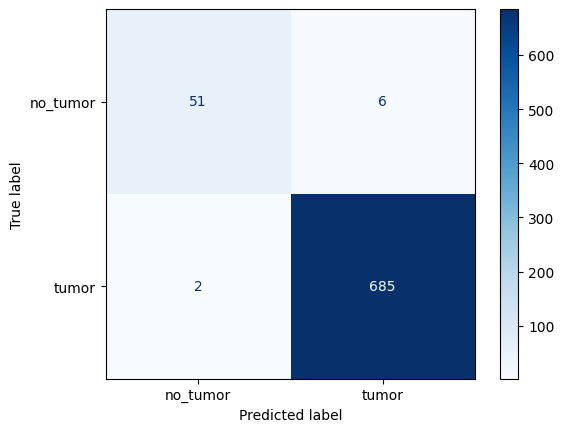

In [17]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

---
## 15. Choosing an Operating Threshold

**Purpose.** In screening, a **missed tumour (false negative)** is the costly mistake. Instead of cutting at 0.5, the threshold $t$ is picked **on the validation set** as the highest value that still gives tumour recall of at least `TARGET_RECALL = 0.95`, and then applied unchanged to the test set. Choosing it on validation keeps the test set untouched.

$$\text{Sensitivity}=\frac{TP}{TP+FN},\quad \text{Specificity}=\frac{TN}{TN+FP},\quad \text{PPV}=\frac{TP}{TP+FP},\quad \text{NPV}=\frac{TN}{TN+FN}$$

**Observed result at t = 0.986** (tumour is the positive class)

| TP | FN | TN | FP |
|---|---|---|---|
| 665 | 22 | 55 | 2 |

| Metric | Value |
|---|---|
| Test prevalence of tumour | 0.923 |
| ROC-AUC | **0.994** |
| Sensitivity | **0.968** |
| Specificity | **0.965** |
| PPV | 0.997 |
| NPV (derived: 55 / 77) | 0.714 |

**Comparison with the default cut-off (Section 14)**

| Operating point | Missed tumours (FN) | False alarms (FP) | Sensitivity | Specificity |
|---|---|---|---|---|
| Default (about 0.5) | **2** | 6 | 0.997 | 0.895 |
| Tuned (t = 0.986) | 22 | **2** | 0.968 | 0.965 |

**Interpretation**

- The target was met: test sensitivity of 0.968 is above 0.95, and the AUC of 0.994 shows that the model ranks tumours above healthy scans almost perfectly.
- The search returns the **strictest** threshold that still satisfies the target. It therefore buys fewer false alarms (6 down to 2) at the cost of **20 additional missed tumours** (2 up to 22).
- NPV is only 0.714: at this threshold, roughly 3 in 10 scans labelled "no tumour" actually contain one.
- If missing a tumour is the worse outcome, a lower threshold or a higher target such as `TARGET_RECALL = 0.99` is the safer choice. The right trade-off is a clinical decision, not a purely statistical one.

In [18]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]     # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'TP {tp} | FN {fn} | TN {tn} | FP {fp}')
    print(f'Test prevalence of {POSITIVE}: {yt.mean():.3f}')
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.986
TP 665 | FN 22 | TN 55 | FP 2
Test prevalence of tumor: 0.923
Test AUC 0.994
Sensitivity 0.968   Specificity 0.965   PPV 0.997


---
## 16. Grad-CAM: A First Look at the Model's Attention

**Purpose.** Grad-CAM shows which image regions pushed the last convolutional block towards the predicted class. For feature map $A^k$ and class score $y^c$:

$$\alpha_k^c=\frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}},\qquad L^c=\operatorname{ReLU}\!\Big(\sum_k \alpha_k^c A^k\Big)$$

The map is up-sampled to 224 x 224, scaled to [0, 1] and overlaid on the scan (red = strongest influence). All parameters are set back to `requires_grad = True` so gradients can flow. The figure shows **three correct predictions** (top row) and **three errors** (bottom row).

**What the figure shows**

- **Correct detections (top row):** all three are gliomas. The heat sits in the central brain region around the ventricles, while the dark background and the skull edge stay cool.
- **Missed glioma (bottom left):** a heavily zoomed, high-contrast slice. The activation sits at the left image edge, away from the bright lesion in the upper left, so the model did not attend to the abnormal region.
- **False alarms (bottom middle and right):** two healthy scans flagged as tumour. In one the heat covers a lateral frontal region and leaks into the background corner; in the other it spreads over the skull base and brainstem.

**Caution.** Heat-maps are a plausibility check, not proof of correct reasoning. Activation over the background or the skull would signal shortcut learning, and this sample does not show a strong case of it, but six images are too few for a firm conclusion.

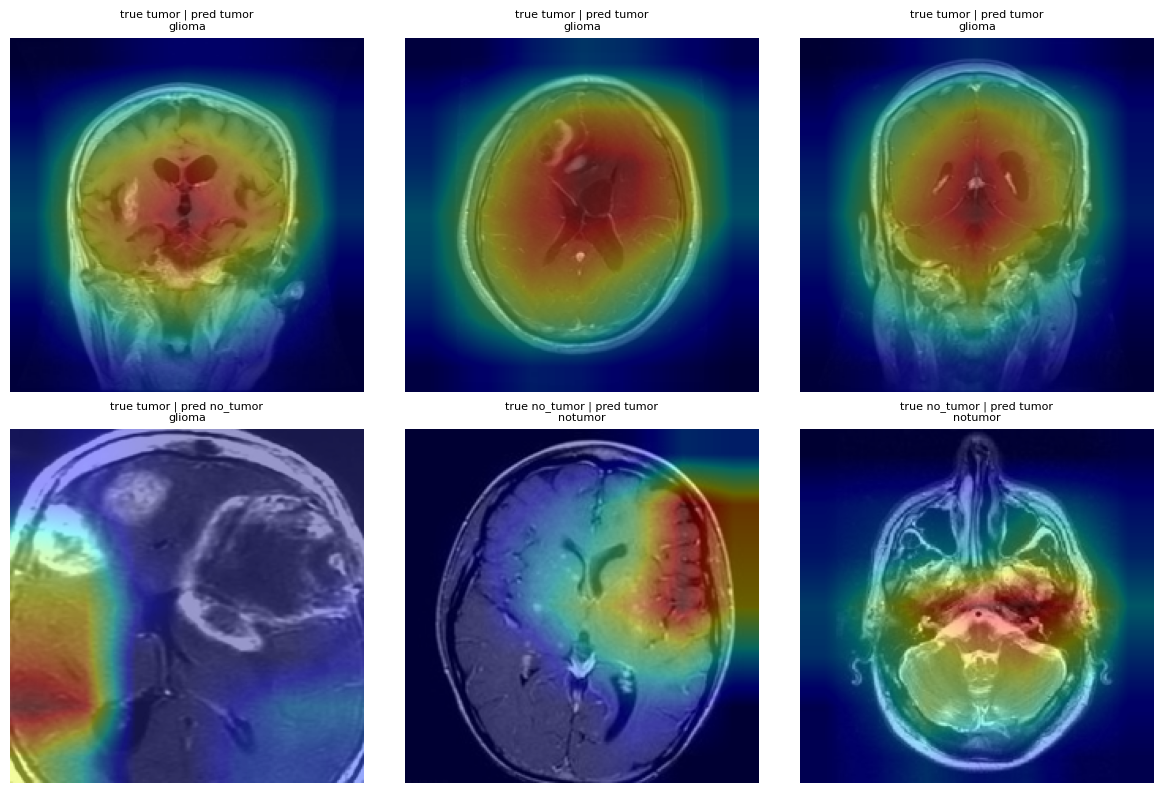

In [19]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)      # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()     # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

---
## 17. Grad-CAM: One Example per Tumour Type, Plus Errors

**Purpose.** A more systematic version of the previous section. With a fixed random generator, the cell picks **one correctly classified image from each original folder** (glioma, meningioma, notumor, pituitary) and **four misclassified images**, giving an 8-panel grid.

**What the figure shows**

- **Top row (correct):** the meningioma example has strong activation over the visible round mass, and the pituitary example concentrates its heat around the sella region at the skull base. The glioma panel is more diffuse across the central brain, and the healthy scan is classified correctly.
- **Bottom row (errors):**
  - *Missed pituitary tumour:* the heat is spread over the upper and posterior brain rather than the sella, which would explain the miss.
  - *Missed glioma:* the same zoomed, high-contrast slice seen in Section 16, so it is one hard image rather than a pattern.
  - *Two false alarms on healthy scans:* strong activation over one hemisphere or the temporal region, where normal anatomy or an intensity asymmetry may look like pathology to the network.

**Reading note.** For a "no tumour" prediction the heat-map marks the evidence for the *healthy* class and is not a lesion locator. The meaningful localisation checks are the tumour predictions.

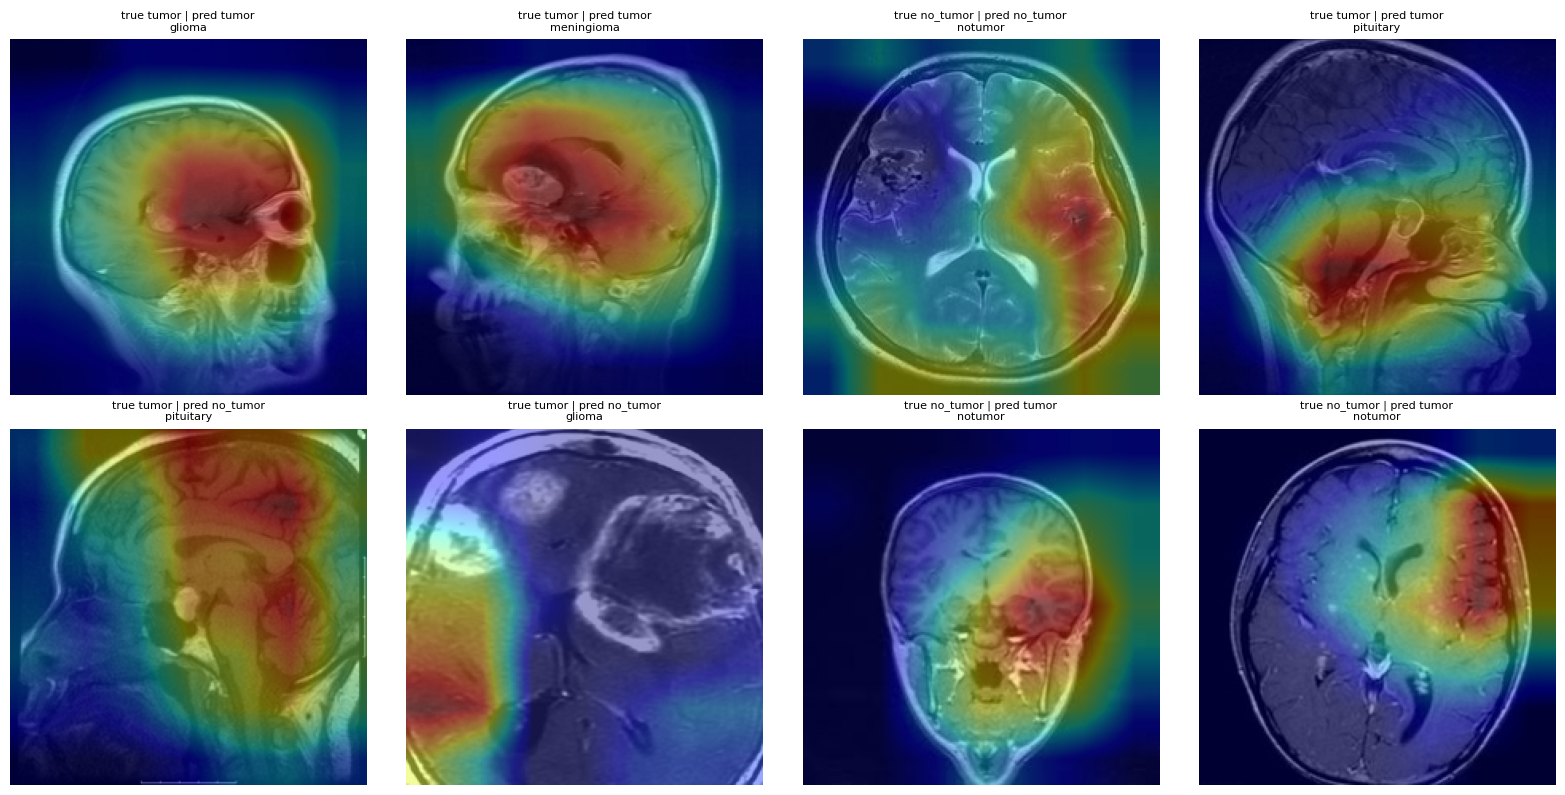

In [20]:
rng = np.random.default_rng(0)
orig = test_df['orig_class'].values
right_pool = np.where(pred == y_test)[0]
wrong_pool = np.where(pred != y_test)[0]
# one correctly classified example per original folder, plus up to 4 mistakes
right = [int(rng.choice(right_pool[orig[right_pool] == c]))
         for c in sorted(set(orig)) if (orig[right_pool] == c).any()]
wrong = rng.choice(wrong_pool, size=min(4, len(wrong_pool)), replace=False).tolist()
idx = right + wrong

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, idx):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
plt.tight_layout()
plt.show()

---
## 18. Saving the Model

**Purpose.** Store everything needed to reload and apply the classifier later in a single checkpoint.

| Key in `week6_model.pt` | Content |
|---|---|
| `state_dict` | All learned weights |
| `classes` | `['no_tumor', 'tumor']` (output order) |
| `backbone` | `resnet18` |
| `img_size` | 224 |
| `grayscale` | `True` (pre-processing at inference must match training) |

**Output:** `/kaggle/working/week6_model.pt`. The tuned threshold **0.986 is not stored** in the file and has to be applied separately at prediction time.

In [21]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


---
## 19. Summary, Limitations and Next Steps

### Key findings

- The four-folder dataset was converted into a **tumour vs. no-tumour** problem with a 3 : 1 class imbalance.
- Data hygiene changed the picture: **187 exact duplicates** were removed, and a near-duplicate audit then removed **260 validation** and **230 test** images that had a twin in the training set. Three quarters of the validation healthy images were affected.
- A ResNet-18 trained in two phases reached a validation macro-F1 of **0.924** after only **about two minutes** of GPU training.
- On the clean test set the default rule gave **98.9% accuracy and 0.961 macro-F1**, with only 8 errors in 744 images.
- The tuned threshold (0.986) reached **sensitivity 0.968, specificity 0.965 and AUC 0.994**, but increased the number of missed tumours from 2 to 22 compared with the default cut-off.

### Limitations

1. **No patient identifiers.** Slices from one patient may still sit in different splits despite the near-duplicate audit, which could make the results optimistic.
2. **Small healthy-class evaluation set** (69 validation, 57 test images). Healthy-class metrics have wide uncertainty, and a single image changes recall by roughly 1.8 points.
3. **One split, one seed.** No repeated cross-validation or confidence intervals were computed.
4. **Binary framing.** Merging glioma, meningioma and pituitary hides whether some tumour types are detected worse than others.
5. **Not clinically validated.** The data comes from a public collection, and no external hospital data was used.

### Suggested next steps

- Re-run threshold selection with a **higher recall target** (for example 0.99) and compare the false-alarm cost.
- Estimate uncertainty with repeated splits or bootstrap confidence intervals.
- Report **per-subtype recall** (glioma, meningioma, pituitary) from the original folder labels.
- Compare against **ResNet-50** or **EfficientNet-B0**, both already supported in the code.
- Add probability calibration, and test on an external dataset with patient-level labels.